# Data Analysis Laboratory 02: Graz Weather Data
Fink Lucas, ESE26

AI Decleration: This script was created with the help of Antigravity (Orchestrator: Gemini 4 Neon, November 2026). AI used to correct and beautify data plots.


## Retrieving weather data for Graz

https://climatephysics.uni-graz.at/de/meteorologische-station/

In [2]:
import openmeteo_requests
import pandas as pd
import requests_cache
from retry_requests import retry

# Setup the Open-Meteo API client
cache_session = requests_cache.CachedSession('.cache', expire_after=-1)
retry_session = retry(cache_session, retries=5, backoff_factor=0.2)
openmeteo = openmeteo_requests.Client(session=retry_session)

# University of Graz main building coordinates
url = "https://archive-api.open-meteo.com/v1/archive"
params = {
    "latitude": 47.0768,
    "longitude": 15.4509,
    "start_date": "2000-01-01",
    "end_date": "2026-11-22",  # Update to today's date
    "hourly": ["temperature_2m", "precipitation", "wind_speed_10m"],
    "timezone": "Europe/Vienna"
}
responses = openmeteo.weather_api(url, params=params)
response = responses[0]

# Process hourly data
hourly = response.Hourly()
hourly_data = {
    "timestamp": pd.date_range(
        start=pd.to_datetime(hourly.Time(), unit="s", utc=True),
        end=pd.to_datetime(hourly.TimeEnd(), unit="s", utc=True),
        freq=pd.Timedelta(seconds=hourly.Interval()),
        inclusive="left"
    ),#.tz_convert("Europe/Vienna"),
    "temperature_2m": hourly.Variables(0).ValuesAsNumpy(),
    "precipitation": hourly.Variables(1).ValuesAsNumpy(),
    "wind_speed_10m": hourly.Variables(2).ValuesAsNumpy(),
}

weather_graz = pd.DataFrame(hourly_data)
print(weather_graz.head())

                  timestamp  temperature_2m  precipitation  wind_speed_10m
0 1999-12-31 23:00:00+00:00      -16.313002            0.0        5.400000
1 2000-01-01 00:00:00+00:00      -17.063002            0.0        5.400000
2 2000-01-01 01:00:00+00:00      -17.413000            0.0        5.623380
3 2000-01-01 02:00:00+00:00      -17.663000            0.0        6.130579
4 2000-01-01 03:00:00+00:00      -17.763000            0.0        5.860375


In [3]:
# Save the weather data as a Parquet file without writing the DataFrame index.
weather_graz.to_parquet("data/weather_graz.parquet", index=False)

## Assignment 1: Data Inspection and Analysis for Weather Graz Data

### DataFrame Inspection

Inspecting the dataset's statistics (`describe()`), total number of elements (`size`), and column names (`columns`).

In [4]:
weather_graz.describe()

,temperature_2m,precipitation,wind_speed_10m
count,235752.000000,235752.000000,235752.000000
mean,10.032466,0.090359,6.129742
std,8.825823,0.388930,3.816668
min,-25.313002,0.000000,0.000000
25%,2.837000,0.000000,3.600000
50%,10.137000,0.000000,5.400000
75%,16.837000,0.000000,7.594208
max,36.287003,20.200001,39.452450


In [5]:
weather_graz.size

943008

In [6]:
weather_graz.columns

Index(['timestamp', 'temperature_2m', 'precipitation', 'wind_speed_10m'],
      dtype='str')

### Data Preparation & Feature Extraction

Copying the weather DataFrame, converting the UTC timestamps to Graz local time (`Europe/Vienna`), and extract `year`, `month`, `hour` and meteorological `season` columns.

In [7]:
import matplotlib.pyplot as plt

# Convert timestamps to Graz local time and derive calendar features
df = weather_graz.copy()
df["timestamp"] = df["timestamp"].dt.tz_convert("Europe/Vienna")
df["year"] = df["timestamp"].dt.year
df["month"] = df["timestamp"].dt.month
df["hour"] = df["timestamp"].dt.hour

season_map = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn",
}
df["season"] = df["month"].map(season_map)

#### 1. Hourly Weather Overview (2000–2026)

Plotting the full hourly time series of temperature (2m), precipitation, and wind speed (10m) to get an overview of trends and extrema.

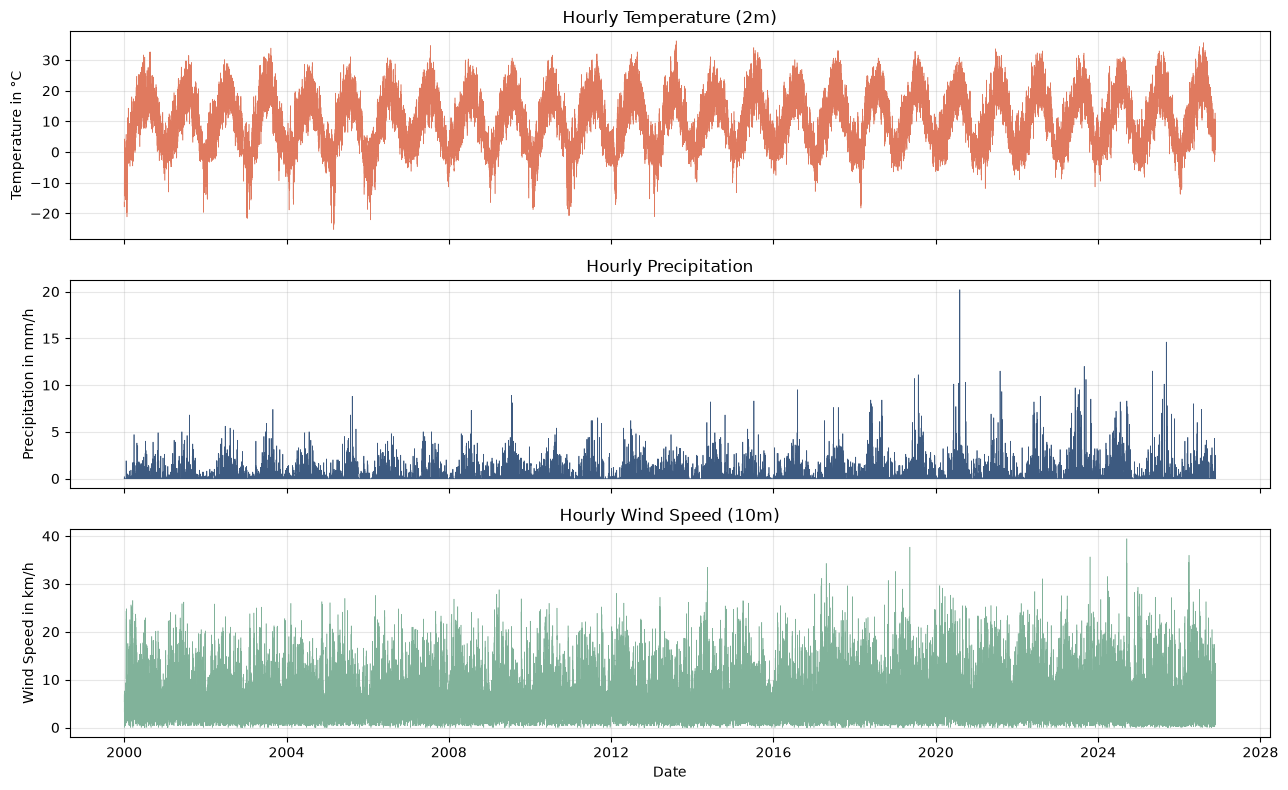

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True)  # 3 stacked subplots sharing one x-axis

axes[0].plot(df["timestamp"], df["temperature_2m"], color="#e07a5f", linewidth=0.4)
axes[0].set_title("Hourly Temperature (2m)")
axes[0].set_ylabel("Temperature in °C")
axes[0].grid(True, alpha=0.3)

axes[1].plot(df["timestamp"], df["precipitation"], color="#3d5a80", linewidth=0.5)
axes[1].set_title("Hourly Precipitation")
axes[1].set_ylabel("Precipitation in mm/h")
axes[1].grid(True, alpha=0.3)

axes[2].plot(df["timestamp"], df["wind_speed_10m"], color="#81b29a", linewidth=0.4)
axes[2].set_title("Hourly Wind Speed (10m)")
axes[2].set_xlabel("Date")
axes[2].set_ylabel("Wind Speed in km/h")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()  # adjust spacing so labels do not overlap
plt.show()

Plot Discussion: The 3 subplots show the features hourly over the entire time frame.  
+ In the first subplot the hourly temperature from the year 2000 to 2026 can be seen. It clearly shows the temperature difference between summer and winter months. Otherwise no real trends can be derived from the plot.
+ The second subpots shows the hourly precipitation. I can be seen that in the more recent years hours with overproportional precipitation has increased.
+ In the third subplot showing the hourly wind speed no real trends can be seen.

#### 2. Annual Total Precipitation in Graz (2000–2025)

Filtering out the incomplete year 2026 first. Summing up the hourly precipitation per calendar year using `groupby` and plotting the yearly totals.

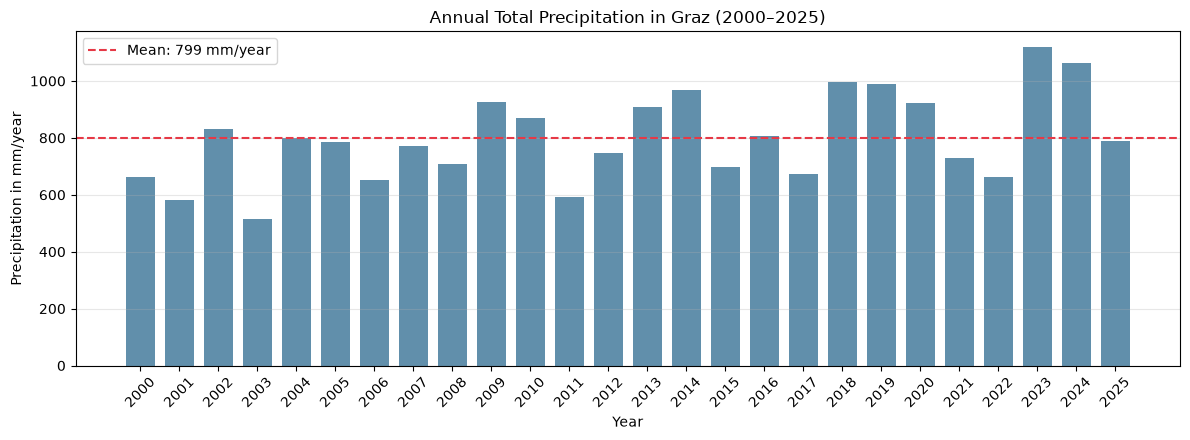

In [9]:
df_complete = df[df["year"] <= 2025] # years with a complete data set
annual_precip = df_complete.groupby("year")["precipitation"].sum() # calculating the annual precipitation
mean_precip = annual_precip.mean() # calculating the annual mean

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(annual_precip.index, annual_precip.values, color="#457b9d", alpha=0.85, width=0.75)
ax.axhline(mean_precip, color="#e63946", linestyle="--", linewidth=1.5, label=f"Mean: {mean_precip:.0f} mm/year")  # horizontal mean reference line
ax.set_title("Annual Total Precipitation in Graz (2000–2025)")
ax.set_xlabel("Year")
ax.set_ylabel("Precipitation in mm/year")
ax.set_xticks(annual_precip.index)  # place a tick at every year
ax.tick_params(axis="x", rotation=45)  # rotate x-axis labels to avoid overlap
ax.grid(True, axis="y", alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

Plot Discussion: This bar chart shows the annual total precipitation in Graz from 2000 to 2025 alongside the long-term mean of 799 mm/year.  
+ Annual precipitation varies from year to year, ranging from a minimum of around 515 mm in 2003 to a peak of over 1100 mm in 2023.
+ Compared to the first decade (2000–2008), where almost every year stayed below the 799 mm average, more recent years show a slight upward tendency.

#### 3. Seasonal Variation by Month

Grouping hourly wind speed values by month and displaying them as boxplots (with outliers hidden) to compare monthly medians and spreads across the year.

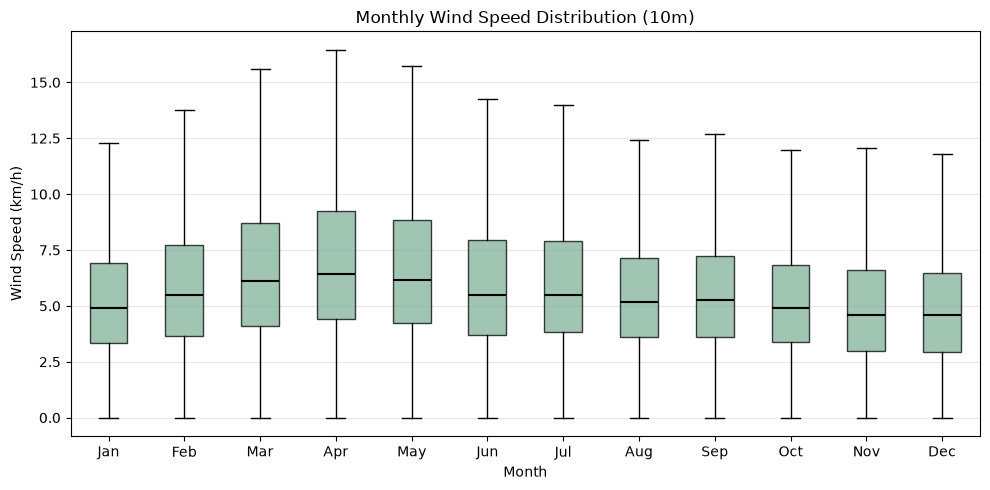

In [10]:
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
# Build a list of 12 NumPy arrays (one per month) as input for boxplot()
wind_by_month = [df.loc[df["month"] == m, "wind_speed_10m"].to_numpy() for m in range(1, 13)]

fig, ax = plt.subplots(figsize=(10, 5))

# showfliers=False hides outliers; patch_artist=True allows filling boxes via boxprops
ax.boxplot(wind_by_month, tick_labels=month_names, showfliers=False, patch_artist=True,
           boxprops=dict(facecolor="#81b29a", alpha=0.75),
           medianprops=dict(color="black", linewidth=1.5))  # style median lines
ax.set_title("Monthly Wind Speed Distribution (10m)")
ax.set_xlabel("Month")
ax.set_ylabel("Wind Speed (km/h)")
ax.grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Plot Discussion: The boxplots show the monthly distribution of hourly 10m wind speeds in Graz across the year (with outliers hidden).  
+ Wind speeds show a slight seasonal pattern, peaking in spring with the highest medians (around 6.1–6.4 km/h) and widest spread.
+ Late autumn and winter months (October to January) are the calmest.

#### 4. Diurnal Temperature Cycle by Season

Computing the average temperature for each combination of meteorological season and local hour of day (0–23), then plot all four seasonal curves together to show how daily warming and cooling patterns change by season.

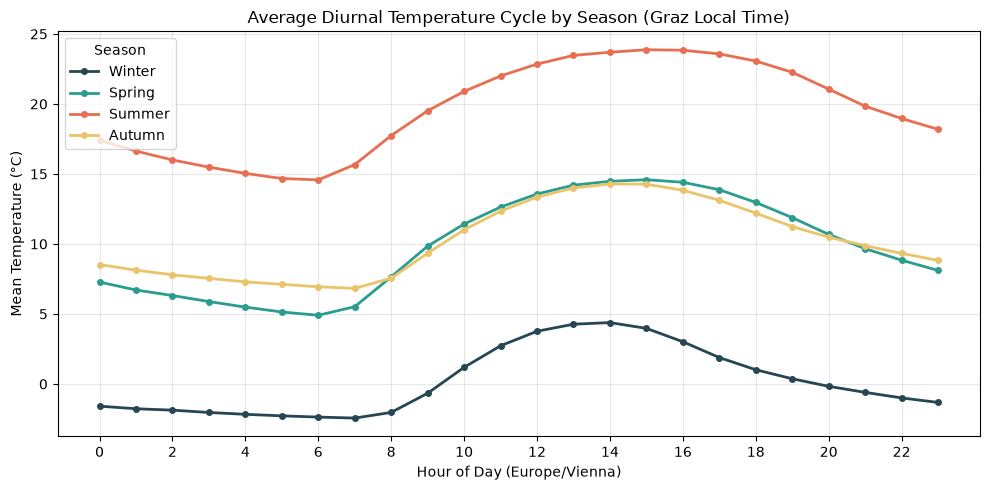

In [11]:
# Average by (season, hour), then pivot season into columns (rows = hours 0–23)
diurnal = df.groupby(["season", "hour"])["temperature_2m"].mean().unstack(level=0)
season_styles = {
    "Winter": "#264653",
    "Spring": "#2a9d8f",
    "Summer": "#e76f51",
    "Autumn": "#e9c46a",
}

fig, ax = plt.subplots(figsize=(10, 5))
for season, color in season_styles.items():
    ax.plot(diurnal.index, diurnal[season], marker="o", markersize=4, linewidth=2, color=color, label=season)

ax.set_title("Average Diurnal Temperature Cycle by Season (Graz Local Time)")
ax.set_xlabel("Hour of Day (Europe/Vienna)")
ax.set_ylabel("Mean Temperature (°C)")
ax.set_xticks(range(0, 24, 2))  # label every 2nd hour
ax.grid(True, alpha=0.3)
ax.legend(title="Season")

plt.tight_layout()
plt.show()

Plot Discussion: This plot compares the average hourly temperature over the course of a day across the four seasons. 
+ All four seasons share a similar daily cycle, reaching their minimum around sunrise and peaking in the early afternoon.

## Generating and Comparing a Climograph for Graz

A climograph consists of temperature and precepitation collected over longer periods of time for a specific location

#### Climograph Construction

Filter to complete years (2000–2025) and aggregate the hourly data in two steps: first to daily minimum/maximum temperature, daily total precipitation, and rainy-day flags (`≥ 1 mm`), and then to monthly values averaged across all years. Finally, plot average min/max temperatures and monthly precipitation on a dual-axis top chart, with average rainy days per month in a bar chart below.

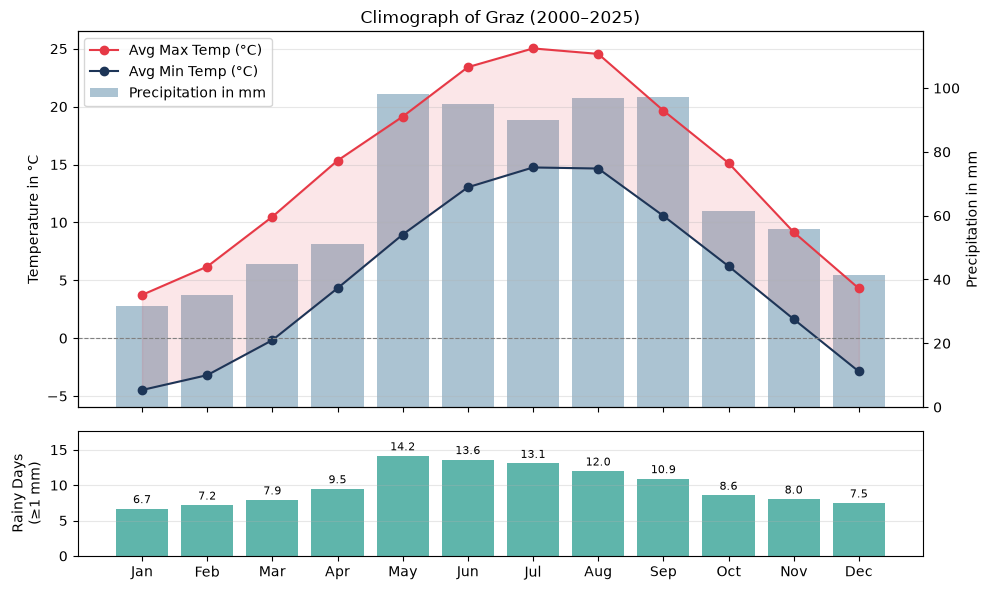

In [13]:
d = df[df["timestamp"].dt.year <= 2025]
# Floor timestamps to midnight to group into calendar days and compute daily stats
daily = d.groupby(d["timestamp"].dt.floor("D")).agg(
    tmin=("temperature_2m", "min"),
    tmax=("temperature_2m", "max"),
    precip=("precipitation", "sum"),
)
daily["rain_day"] = daily["precip"] >= 1.0  # True/False flag (sums to rainy-day count)

# Aggregate per (year, month), then average across years by month (index level 1)
clim = (
    daily.groupby([daily.index.year, daily.index.month])
    .agg(tmin=("tmin", "mean"), tmax=("tmax", "mean"), precip=("precip", "sum"), rain_days=("rain_day", "sum"))
    .groupby(level=1).mean()
)
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

# 2 stacked subplots (top 3x taller than bottom) sharing the month x-axis
fig, (ax1, ax3) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax2 = ax1.twinx()  # secondary right y-axis sharing ax1's x-axis

ax2.bar(months, clim["precip"], color="#457b9d", alpha=0.45, label="Precipitation in mm")
ax1.plot(months, clim["tmax"], "o-", color="#e63946", label="Avg Max Temp (°C)")
ax1.plot(months, clim["tmin"], "o-", color="#1d3557", label="Avg Min Temp (°C)")
ax1.fill_between(months, clim["tmin"], clim["tmax"], color="#e63946", alpha=0.12)  # shade min-to-max temp range
ax1.axhline(0, color="gray", ls="--", lw=0.8)  # 0 °C reference line

# Keep temperature lines (ax1) drawn in front of precipitation bars (ax2)
ax1.set_zorder(ax2.get_zorder() + 1)
ax1.patch.set_visible(False)  # make ax1 background transparent so ax2 bars show through
ax1.set(title="Climograph of Graz (2000–2025)", ylabel="Temperature in °C")
ax2.set(ylabel="Precipitation in mm", ylim=(0, clim["precip"].max() * 1.2))
ax1.grid(axis="y", alpha=0.3)

# Combine legend handles/labels from both y-axes into a single legend
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left")

bars = ax3.bar(months, clim["rain_days"], color="#2a9d8f", alpha=0.75)
ax3.bar_label(bars, fmt="%.1f", fontsize=8, padding=2)  # display bar values to 1 decimal place
ax3.set(ylabel="Rainy Days\n(≥1 mm)", ylim=(0, clim["rain_days"].max() * 1.25))
ax3.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Plot Discussion: The climograph summarizes Graz's monthly average minimum/maximum temperatures and precipitation (top) together with the average number of rainy days per month (bottom) from 2000 to 2025.  
+ Temperatures show a clear seasonal cycle, ranging from average lows below 0 °C in winter to average afternoon highs of ~25 °C in July and August.
+ Precipitation is concentrated in the warmer months from May to September while winter is comparatively dry.
+ The rainy-day distribution follows a similar pattern, peaking in May and dropping to a minimum in January. 

Climograph from https://www.wetterkontor.de/de/klima/klima2.asp?land=at&stat=11240 from 1991 to 2020 instead of 2000 to 2026

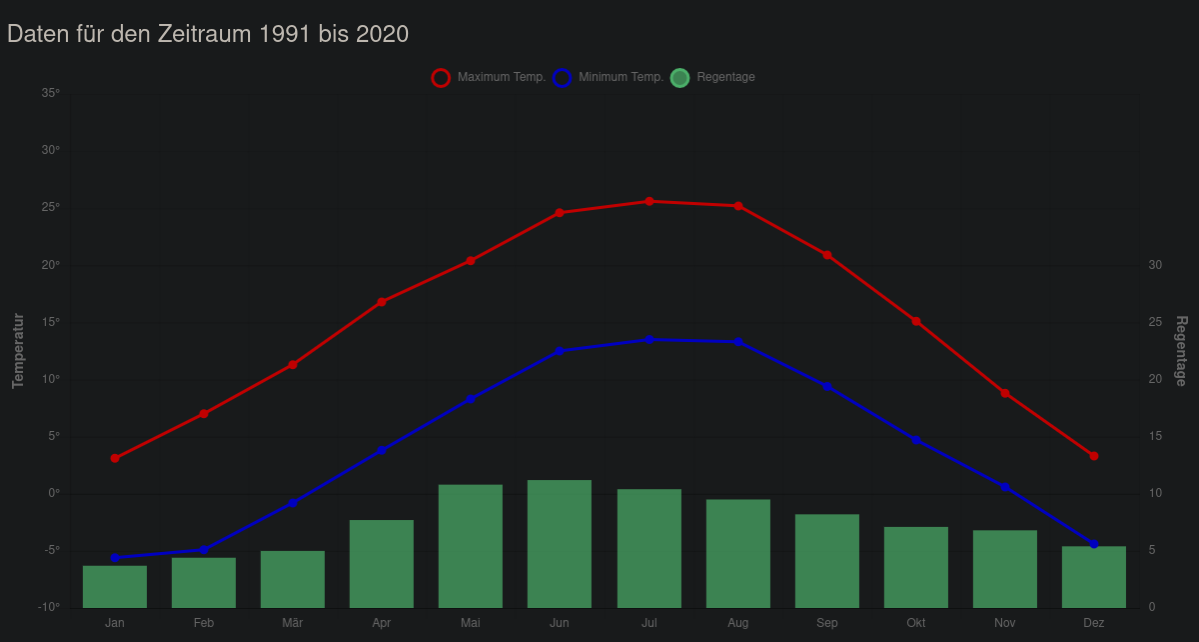

The Climograph from WetterKontor shows basically the same behaviour except for small deviations from the generated one.